# Perbandingan Model Regresi Linear — Perkembangan Diabetes

**Jenis proyek:** Supervised Machine Learning — Regresi  
**Dataset:** Diabetes dari Scikit-learn  
**Target:** `target` — ukuran numerik perkembangan penyakit satu tahun setelah pengukuran awal.

> **Penting:** Analisis ini hanya untuk pembelajaran dan latihan pemodelan statistik. Hasilnya bukan alat diagnosis atau pengobatan, dan tidak boleh digunakan untuk mengambil keputusan medis seseorang.

## Alur pengerjaan
1. Mengenal dataset dan setiap variabel.
2. Menentukan tujuan analisis.
3. Memeriksa kualitas data dan hubungan antarvariabel.
4. Membagi data menjadi data latih dan data uji.
5. Melatih dan membandingkan beberapa variasi regresi.
6. Mengevaluasi model menggunakan MAE, RMSE, dan R².
7. Memahami koefisien dan residual model.
8. Membahas keterbatasan serta pengembangan selanjutnya.

## 1. Ringkasan Dataset
Dataset memiliki **442 baris data**, **10 fitur input**, dan **1 target numerik**. Fitur input meliputi `age`, `sex`, `bmi`, `bp`, dan `s1` sampai `s6`. Target `target` menunjukkan ukuran perkembangan diabetes satu tahun setelah pengukuran awal.

Lihat `../data/data_dictionary.csv` untuk ringkasan arti setiap kolom.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
DATA_PATH = Path("../data/diabetes_progression.csv")
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())
display(df.describe().T)

Dataset shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


None

,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


### Struktur dan kualitas dataset
- **Jumlah baris:** 442
- **Fitur prediksi:** age, sex, bmi, bp, s1, s2, s3, s4, s5, s6
- **Target:** target
- Fitur pada dataset sumber sudah distandardisasi.
- Kita tetap perlu memeriksa nilai kosong dan data duplikat, bukan langsung menganggap data sudah bersih.

In [2]:
print("Missing values per column:")
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Target summary:")
display(df["target"].describe())

Missing values per column:


age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Duplicate rows: 0
Target summary:


count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64

## 2. Tujuan Analisis

Tujuan analisis ini adalah memprediksi nilai numerik pada kolom `target` menggunakan pengukuran awal yang tersedia. Kita akan membandingkan beberapa pendekatan regresi untuk mengetahui model mana yang memberikan hasil prediksi paling baik pada data yang belum pernah dilihat sebelumnya.

Perlu diingat, analisis ini berfokus pada prediksi. Koefisien atau hubungan antarvariabel tidak membuktikan bahwa suatu fitur menyebabkan perubahan pada target.

## 3. Eksplorasi Data (EDA)

Grafik berikut membantu kita melihat sebaran nilai target dan hubungan awal beberapa fitur dengan target. Karena fitur sudah distandardisasi, nilainya tidak sama dengan satuan asli dalam pengukuran klinis.

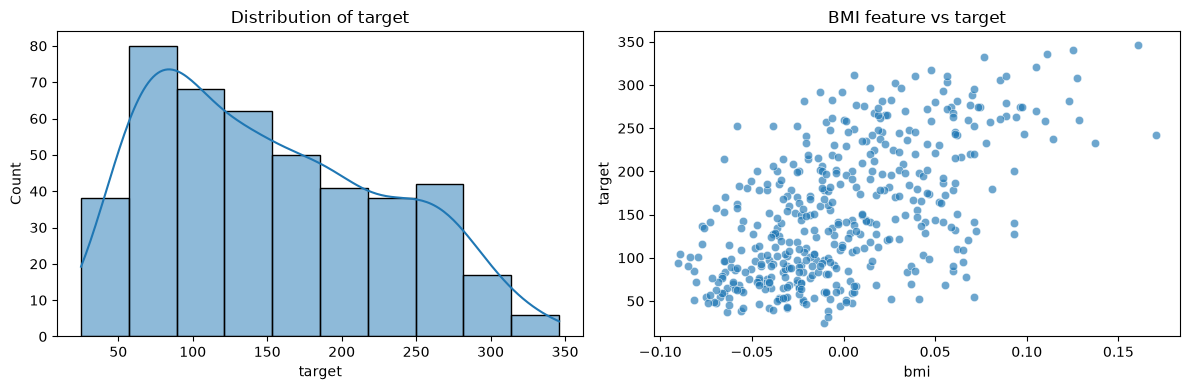

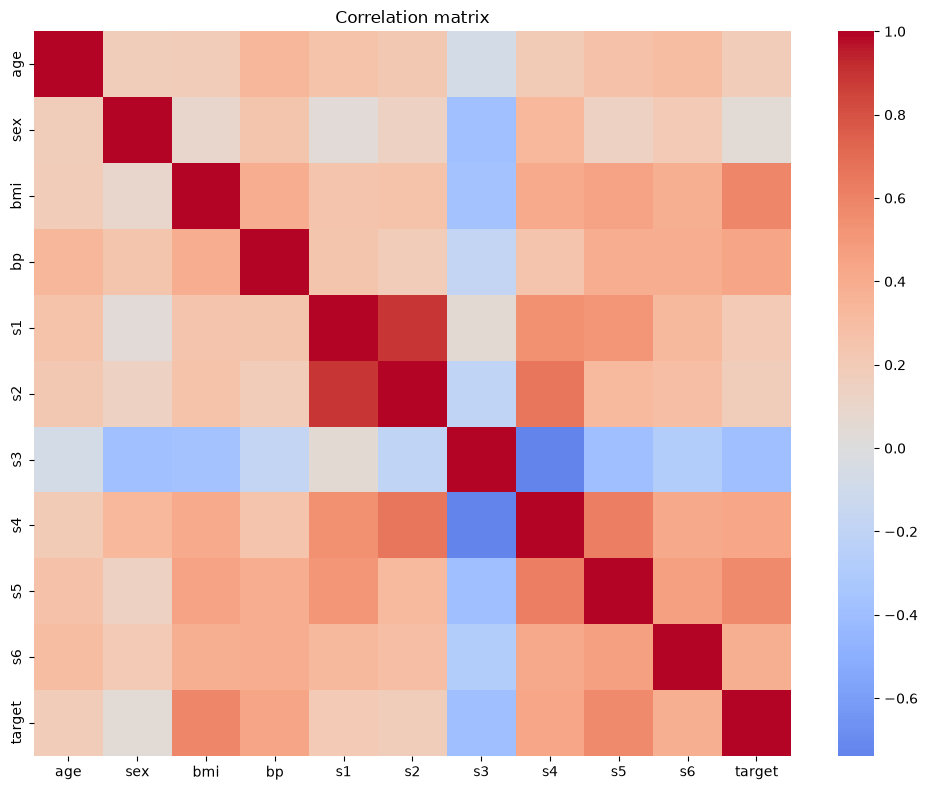

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["target"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of target")
sns.scatterplot(data=df, x="bmi", y="target", alpha=0.65, ax=axes[1])
axes[1].set_title("BMI feature vs target")
plt.tight_layout()
plt.show()

corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

## 4. Pembagian Data dan Strategi Pemodelan

Data dibagi menjadi 80% data latih dan 20% data uji. Data uji disimpan untuk evaluasi akhir, sehingga model tidak belajar dari data tersebut saat proses pelatihan.

Proses standardisasi dan pembentukan fitur ditempatkan di dalam pipeline. Dengan cara ini, proses tersebut hanya mempelajari parameter dari data latih dan mengurangi risiko kebocoran informasi (*data leakage*).

### Model yang dibandingkan
1. **Mean Baseline:** selalu memprediksi nilai rata-rata target dari data latih. Ini menjadi patokan sederhana.
2. **Simple Linear Regression:** hanya menggunakan fitur BMI (`bmi`).
3. **Multiple Linear Regression:** menggunakan seluruh 10 fitur.
4. **Polynomial Regression (derajat 2):** menambahkan fitur berpangkat dan kombinasi hingga derajat dua, lalu melakukan regresi linear.
5. **Ridge Regression:** regresi dengan regularisasi L2; nilai alpha dipilih melalui validasi silang.
6. **Lasso Regression:** regresi dengan regularisasi L1; nilai alpha dipilih melalui validasi silang.

Polynomial Regression tetap termasuk model yang linear terhadap koefisiennya, meskipun dapat menggambarkan pola melengkung pada fitur awal.

In [4]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
X_train_bmi = X_train[["bmi"]]
X_test_bmi = X_test[["bmi"]]

models = {
    "Mean baseline": Pipeline([
        ("model", DummyRegressor(strategy="mean"))
    ]),
    "Simple Linear Regression (BMI)": Pipeline([
        ("scale", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Multiple Linear Regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Polynomial Regression (degree 2)": Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scale", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", RidgeCV(alphas=np.logspace(-3, 3, 25)))
    ]),
    "Lasso Regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LassoCV(cv=5, max_iter=20000, random_state=RANDOM_STATE))
    ])
}

fitted_models = {}
predictions = {}
rows = []

for name, model in models.items():
    if name == "Simple Linear Regression (BMI)":
        model.fit(X_train_bmi, y_train)
        pred = model.predict(X_test_bmi)
    else:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

    fitted_models[name] = model
    predictions[name] = pred
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

comparison = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
display(comparison)

,Model,MAE,RMSE,R2
0,Lasso Regression,42.793029,52.919631,0.471422
1,Ridge Regression,42.811999,53.777454,0.454147
2,Multiple Linear Regression,42.794095,53.853446,0.452603
3,Polynomial Regression (degree 2),43.581693,55.641965,0.415640
4,Simple Linear Regression (BMI),52.259976,63.732456,0.233350
5,Mean baseline,64.006461,73.222493,-0.011963


## 5. Perbandingan Model dan Pemilihan Model

Cara membaca metrik:
- **MAE:** rata-rata besar kesalahan absolut prediksi. Semakin kecil, semakin baik.
- **RMSE:** memberi penalti lebih besar pada kesalahan prediksi yang jauh. Semakin kecil, semakin baik.
- **R²:** menunjukkan seberapa besar variasi target yang dapat dijelaskan model pada data uji. Nilai lebih tinggi umumnya lebih baik. Nilai negatif berarti model lebih buruk daripada patokan prediksi rata-rata pada data uji.

Dalam proyek ini, model dipilih terutama berdasarkan **RMSE paling rendah**, sedangkan MAE dan R² digunakan sebagai pertimbangan tambahan. Jangan memilih model hanya dari performa pada data latih.

Best model by test RMSE: Lasso Regression


,Model,MAE,RMSE,R2
0,Lasso Regression,42.793,52.920,0.471
1,Ridge Regression,42.812,53.777,0.454
2,Multiple Linear Regression,42.794,53.853,0.453
3,Polynomial Regression (degree 2),43.582,55.642,0.416
4,Simple Linear Regression (BMI),52.260,63.732,0.233
5,Mean baseline,64.006,73.222,-0.012


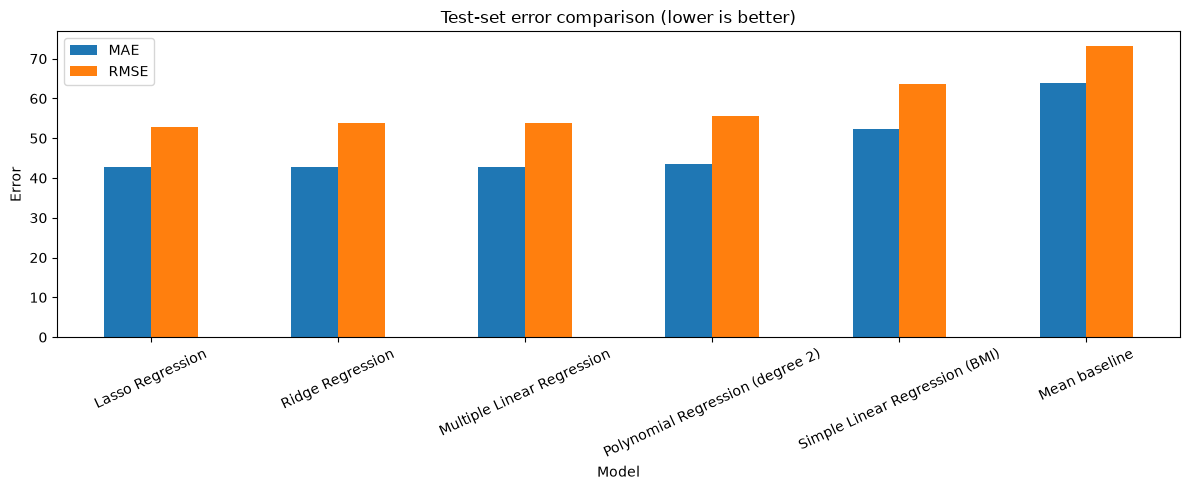

In [5]:
best_model_name = comparison.loc[0, "Model"]
print("Best model by test RMSE:", best_model_name)
display(comparison.style.format({"MAE":"{:.3f}", "RMSE":"{:.3f}", "R2":"{:.3f}"}))

ax = comparison.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar", figsize=(12, 5), rot=25
)
ax.set_title("Test-set error comparison (lower is better)")
ax.set_ylabel("Error")
plt.tight_layout()
plt.show()

comparison.set_index("Model").to_csv("../results/model_comparison.csv")

## 6. Temuan Utama dan Interpretasi Model

Gunakan hasil yang benar-benar muncul setelah notebook dijalankan. Bahas beberapa pertanyaan berikut:
- Model mana yang menghasilkan RMSE data uji paling rendah?
- Apakah regularisasi Ridge atau Lasso membantu dibanding Multiple Linear Regression biasa?
- Apakah Polynomial Regression meningkatkan hasil prediksi sehingga penambahan kompleksitasnya layak?
- Seberapa jauh model terpilih lebih baik dibanding Mean Baseline?
- Fitur mana yang memiliki koefisien positif atau negatif paling besar pada model linear terpilih?

**Perlu diingat:** koefisien menggambarkan hubungan fitur dengan target di dalam model, bukan bukti sebab-akibat atau saran medis.

,coefficient
bmi,26.185688
s5,21.962318
bp,15.041788
s3,-11.071885
sex,-7.980570
s1,-4.805483
s6,1.738785
age,0.000000
s2,-0.000000
s4,0.000000


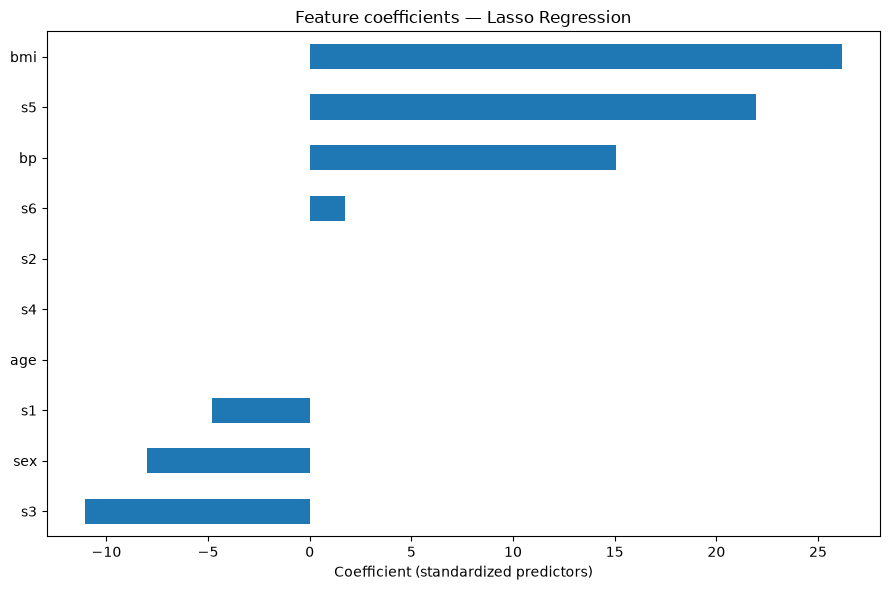

In [6]:
# Coefficients are directly comparable here because predictors were standardized
# inside the pipeline. Polynomial terms are intentionally not expanded into
# a simple feature-level clinical explanation.
selected = fitted_models[best_model_name]
if best_model_name in ["Multiple Linear Regression", "Ridge Regression", "Lasso Regression"]:
    coef = pd.Series(
        selected.named_steps["model"].coef_,
        index=X.columns
    ).sort_values(key=np.abs, ascending=False)
    display(coef.to_frame("coefficient"))
    coef.sort_values().plot(kind="barh", figsize=(9, 6))
    plt.title(f"Feature coefficients — {best_model_name}")
    plt.xlabel("Coefficient (standardized predictors)")
    plt.tight_layout()
    plt.show()
else:
    print("Selected model is not a plain all-feature linear model; interpret its terms accordingly.")

## 7. Pemeriksaan Residual

Residual adalah selisih antara nilai sebenarnya dan nilai prediksi. Model yang cukup baik umumnya tidak menunjukkan pola yang terlalu jelas pada residual.

Grafik residual dapat membantu menemukan pola non-linear, variasi kesalahan yang tidak merata, data yang menyimpang, atau kecenderungan model untuk memprediksi terlalu tinggi maupun terlalu rendah.

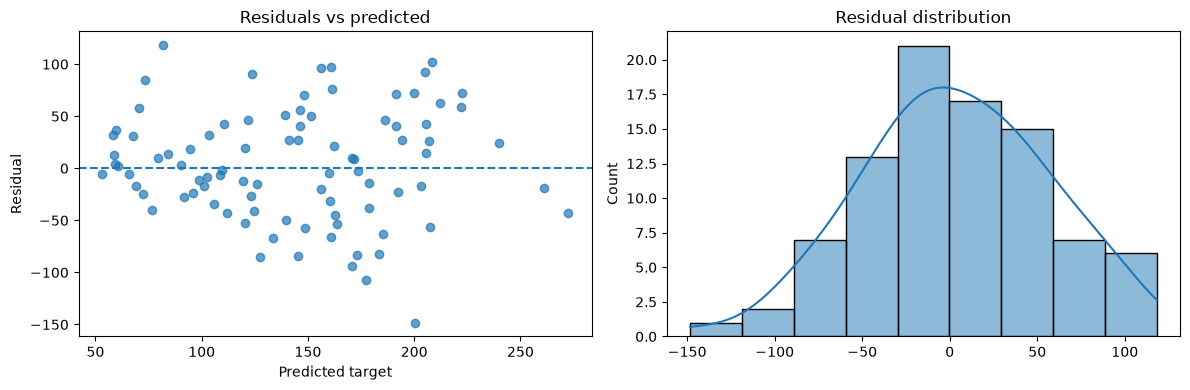

In [7]:
best_pred = predictions[best_model_name]
residuals = y_test.to_numpy() - best_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(best_pred, residuals, alpha=0.7)
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Predicted target")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs predicted")

sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Residual distribution")
plt.tight_layout()
plt.show()

## 8. Keterbatasan dan Langkah Selanjutnya

### Keterbatasan
- Dataset relatif kecil, hanya 442 observasi.
- Fitur input sudah distandardisasi sehingga nilainya tidak langsung dapat dibaca dalam satuan pengukuran asli.
- Satu kali pembagian data latih dan uji dapat menghasilkan nilai evaluasi yang berbeda jika pembagiannya berubah.
- Target merupakan ukuran perkembangan numerik, bukan diagnosis atau ukuran langsung kondisi kesehatan saat ini.
- Model linear mungkin belum menangkap hubungan non-linear dan interaksi yang lebih rumit.
- Dataset belum tentu mewakili semua kelompok populasi atau kondisi saat ini.
- Hubungan statistik dan koefisien model tidak membuktikan hubungan sebab-akibat.

### Hal yang bisa dikembangkan
1. Mengulang evaluasi dengan validasi silang berulang dan melaporkan variasi hasilnya.
2. Mengatur parameter Ridge dan Lasso dengan proses validasi yang tepat.
3. Membandingkan model non-linear sebagai eksperimen tambahan, tanpa menghilangkan perbandingan regresi.
4. Memeriksa data yang sangat berpengaruh dan pola residual.
5. Menjelaskan arti metrik dalam skala target agar hasilnya lebih mudah dipahami pembaca.
6. Meminta masukan ahli bidang terkait sebelum membuat interpretasi di luar konteks pembelajaran.

## 9. Kesimpulan

Lengkapi bagian ini setelah notebook dijalankan. Sebutkan model yang dipilih, nilai MAE/RMSE/R² pada data uji, perbandingannya dengan model baseline dan variasi regresi lainnya, temuan utama, serta keterbatasan analisis.

## Daftar periksa sebelum dikumpulkan
- [ ] Notebook berhasil dijalankan dari awal sampai akhir.
- [ ] Dataset dan data dictionary tersedia.
- [ ] Ringkasan dataset dijelaskan.
- [ ] Tujuan analisis ditulis dengan jelas.
- [ ] Beberapa variasi regresi linear sudah dibandingkan.
- [ ] Pemilihan model dijelaskan menggunakan metrik data uji.
- [ ] Temuan utama didukung oleh hasil yang benar-benar muncul.
- [ ] Keterbatasan dan langkah selanjutnya dibahas.
- [ ] Tidak ada informasi pribadi atau sensitif pasien.